# 01 — Logistic Regression Baseline & Dummy Benchmark

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix,
    classification_report, brier_score_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')


## 2. Ingestion & Stratified Split Setup (Target: Loan_Default)


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target: 1 = Default (Yes), 0 = Non-default (No)
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude target leakage and identifiers
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)


## 3. Preprocessing ColumnTransformer Architecture


In [3]:
numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 4. Naive Baseline: DummyClassifier


In [4]:
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)

y_dummy_pred = dummy_clf.predict(X_test)
dummy_acc = accuracy_score(y_test, y_dummy_pred)
dummy_rec = recall_score(y_test, y_dummy_pred, zero_division=0)
dummy_f1 = f1_score(y_test, y_dummy_pred, zero_division=0)

print(f'Dummy Classifier (Predicts "No" for 100% of applicants):')
print(f'  Accuracy:  {dummy_acc:.4f} ({dummy_acc*100:.2f}%)')
print(f'  Recall:    {dummy_rec:.4f} ({dummy_rec*100:.2f}%)')
print(f'  F1 Score:  {dummy_f1:.4f}')


Dummy Classifier (Predicts "No" for 100% of applicants):
  Accuracy:  0.8020 (80.20%)
  Recall:    0.0000 (0.00%)
  F1 Score:  0.0000


## 5. Fitting Logistic Regression Baseline


In [5]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', log_reg)
])

# Fit on training data
lr_pipeline.fit(X_train, y_train)

# Predictions
y_train_pred = lr_pipeline.predict(X_train)
y_train_prob = lr_pipeline.predict_proba(X_train)[:, 1]

y_test_pred = lr_pipeline.predict(X_test)
y_test_prob = lr_pipeline.predict_proba(X_test)[:, 1]

# Metrics evaluation
def evaluate_performance(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1_Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_prob),
        'Brier_Score': brier_score_loss(y_true, y_prob)
    }

train_metrics = evaluate_performance(y_train, y_train_pred, y_train_prob)
test_metrics = evaluate_performance(y_test, y_test_pred, y_test_prob)

df_perf = pd.DataFrame([train_metrics, test_metrics], index=['Train (8,000)', 'Test (2,000)'])
display(df_perf.round(4))


,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Brier_Score
"Train (8,000)",0.869,0.7326,0.5316,0.6161,0.8945,0.0939
"Test (2,000)",0.865,0.7203,0.5202,0.6041,0.8905,0.0964


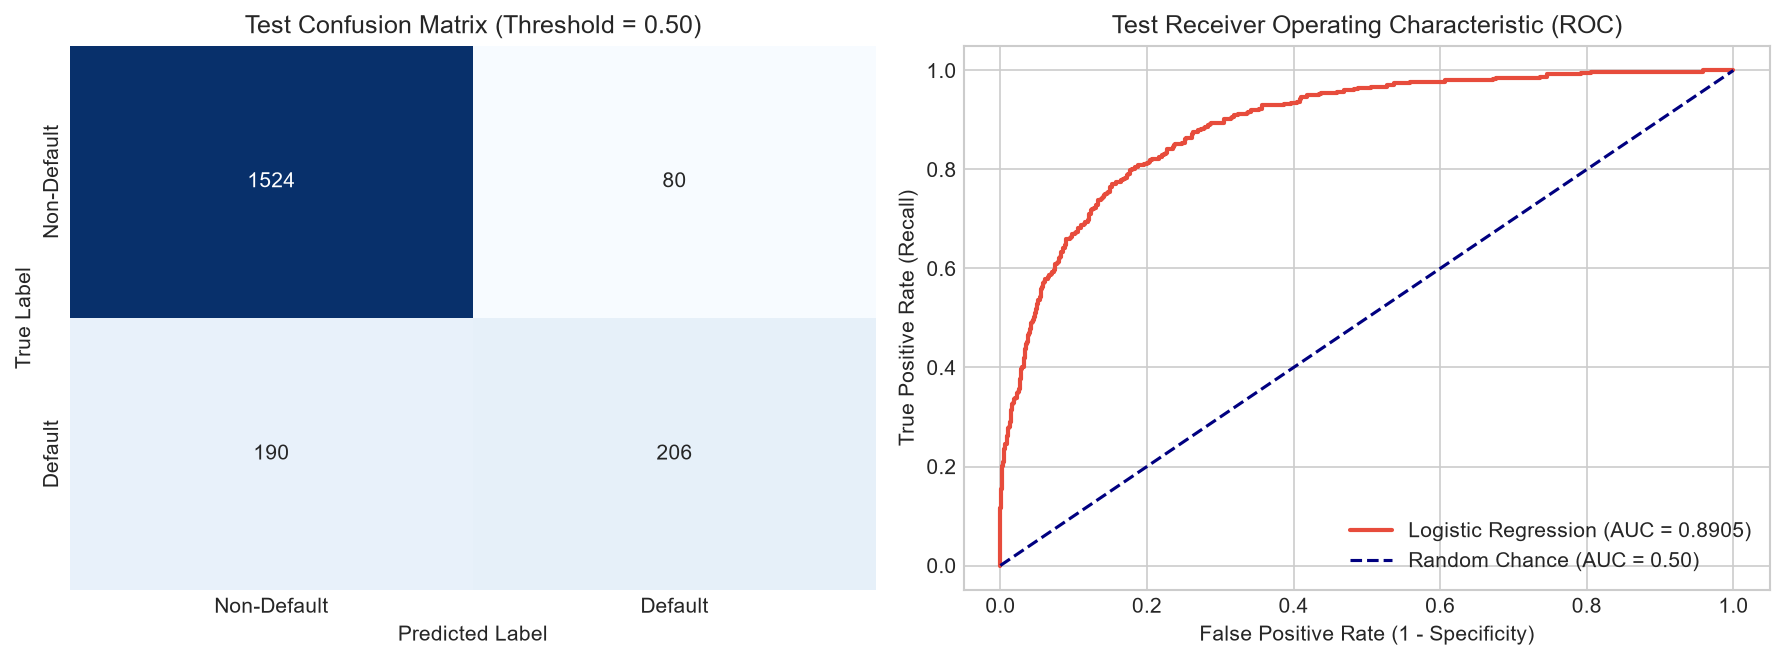

In [6]:
# Visualise Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Non-Default', 'Default'], yticklabels=['Non-Default', 'Default'])
axes[0].set_title('Test Confusion Matrix (Threshold = 0.50)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

fpr, tpr, _ = roc_curve(y_test, y_test_prob)
axes[1].plot(fpr, tpr, color='#e74c3c', lw=2, label=f'Logistic Regression (AUC = {test_metrics["ROC_AUC"]:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.50)')
axes[1].set_title('Test Receiver Operating Characteristic (ROC)')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_lr_baseline_roc_cm.png', dpi=150)
plt.show()


## 6. Stratified 5-Fold Cross-Validation Evaluation


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results = cross_validate(lr_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

print('=== 5-Fold Cross-Validation Results (Training Set Only) ===')
cv_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'CV Mean': [cv_results[f'test_{m}'].mean() for m in scoring],
    'CV Std': [cv_results[f'test_{m}'].std() for m in scoring],
    'Test Score': [test_metrics['Accuracy'], test_metrics['Precision'], test_metrics['Recall'], test_metrics['F1_Score'], test_metrics['ROC_AUC']]
})
display(cv_summary.round(4))


=== 5-Fold Cross-Validation Results (Training Set Only) ===


,Metric,CV Mean,CV Std,Test Score
0,Accuracy,0.8652,0.0048,0.8650
1,Precision,0.7194,0.0142,0.7203
2,Recall,0.5221,0.0219,0.5202
3,F1 Score,0.6049,0.0185,0.6041
4,ROC-AUC,0.8889,0.0057,0.8905


## 7. Mathematical Odds and Probability Calculations


In [8]:
# Calculation
z = -1.35
odds_val = np.exp(z)
prob_val = 1.0 / (1.0 + np.exp(-z))
print(f'Log-odds z = {z}')
print(f'Odds of default: {odds_val:.4f}')
print(f'Probability of default: {prob_val:.4f} ({prob_val*100:.2f}%)')

# Calculation
beta_late = 0.35
or_late = np.exp(beta_late)
pct_inc = (or_late - 1.0) * 100
print(f'\nCoefficient beta = {beta_late}')
print(f'Odds Ratio = {or_late:.4f}')
print(f'Percentage increase in odds per 1 unit increase: +{pct_inc:.2f}%')


Log-odds z = -1.35
Odds of default: 0.2592
Probability of default: 0.2059 (20.59%)

Coefficient beta = 0.35
Odds Ratio = 1.4191
Percentage increase in odds per 1 unit increase: +41.91%


## 8. Standardized Coefficients & Top Predictors


In [9]:
fitted_preprocessor = lr_pipeline.named_steps['prep']
fitted_lr = lr_pipeline.named_steps['clf']

feature_names = (
    numeric_cols +
    list(fitted_preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

coefficients = fitted_lr.coef_[0]

df_coef = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients),
    'Odds_Ratio_per_SD': np.exp(coefficients)
}).sort_values('Abs_Coefficient', ascending=False).reset_index(drop=True)

df_coef.to_csv('../../outputs/tables/loan_default_lr_coefficients.csv', index=False)

print('=== Top 10 Standardized Predictors by Absolute Coefficient ===')
display(df_coef.head(10))


=== Top 10 Standardized Predictors by Absolute Coefficient ===


,Feature,Coefficient,Abs_Coefficient,Odds_Ratio_per_SD
0,Previous_Default,1.246376,1.246376,3.477718
1,Credit_Score,-1.171916,1.171916,0.309773
2,Employment_Type_Unemployed,0.843768,0.843768,2.325111
3,Employment_Type_Retired,-0.811357,0.811357,0.444255
4,Has_Co_Applicant,-0.764840,0.764840,0.465408
5,Debt_to_Income,0.584494,0.584494,1.794082
6,Salary_Account_With_Bank,-0.583472,0.583472,0.557958
7,Loan_Purpose_Business,0.434501,0.434501,1.544192
8,Late_Payments_2Y,0.406806,0.406806,1.502012
9,Employment_Type_Salaried,-0.382950,0.382950,0.681847
